### Example of how to use functions to train the NN models and plot the metrics

In [3]:
import sys
sys.path.append('src') # ammend system path so that import works

In [4]:
# import necessary functions and classes
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision import transforms
from utils import ImageDatasetFromFolders
from torch.utils.data import Dataset, DataLoader
from train_test_utils import train_model, test_model
from plotting import plot_learning_curves
from utils import NeuralNetwork
from torch import nn
from config import ProjectConfig

In [5]:
config = ProjectConfig() # create consistent settings for the project

In [7]:
# load random seeds and choose the best available device for training

SEED = config.seed

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)
base = os.getcwd()

train_dir = os.path.join(base, "data/Train")
val_dir = os.path.join(base, "data/Validation")
test_dir = os.path.join(base, "data/Test")

# lower resolution for now - testing purposes
image_size = (64, 64)
batch_size = 32

transform = transforms.Compose([transforms.Resize(image_size),transforms.ToTensor()])

Using device: cpu


In [8]:
from utils import ImageDatasetFromFolders

train_data = ImageDatasetFromFolders(train_dir, transform)
val_data = ImageDatasetFromFolders(val_dir, transform)
test_data = ImageDatasetFromFolders(test_dir, transform)

print("Classes:", train_data.class_names)
print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images:", len(test_data))

# check if they have the same class names to avoid silent declne in performance
assert (train_data.class_names == val_data.class_names == test_data.class_names)

train_dl = DataLoader(train_data,batch_size=batch_size,shuffle=True)

val_dl = DataLoader(val_data,batch_size=batch_size,shuffle=False)

test_dl = DataLoader(test_data,batch_size=batch_size,shuffle=False)

Classes: ['Healthy', 'Powdery', 'Rust']
Training images: 1322
Validation images: 60
Test images: 150


### Training Pytorch NN

In [9]:
# load fully connected pytorch NN architecture

model = NeuralNetwork(num_classes=3).to(device)
print(model)

criterion = nn.CrossEntropyLoss() # cross entropy loss for multiclass classification
optimizer = torch.optim.Adam(model.parameters(),lr=0.0001,weight_decay=5e-4) # ADAM optimizer

NeuralNetwork(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=12288, out_features=512, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=512, out_features=128, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.3, inplace=False)
    (7): Linear(in_features=128, out_features=3, bias=True)
  )
)


In [10]:
filename = 'pytorch_nn' # filename for the saved models and plots
# train model to get history and training time
history_pytorch_nn, training_time_pytorch_nn = train_model(model, test_dl, val_dl, criterion, optimizer, device, config, save_files=True,file_name=filename, num_epochs=5)
print(history_pytorch_nn)
print(training_time_pytorch_nn)

relevant directories created ... 
Epoch [1/5] | Train Loss: 1.4542 | Train Acc: 0.2733 | Val Loss: 1.1090 | Val Acc: 0.3833
Epoch [2/5] | Train Loss: 1.1070 | Train Acc: 0.2800 | Val Loss: 1.0956 | Val Acc: 0.3500
Epoch [3/5] | Train Loss: 1.0983 | Train Acc: 0.3867 | Val Loss: 1.0974 | Val Acc: 0.3333
Epoch [4/5] | Train Loss: 1.1231 | Train Acc: 0.2867 | Val Loss: 1.0997 | Val Acc: 0.4667
Epoch [5/5] | Train Loss: 1.1337 | Train Acc: 0.3000 | Val Loss: 1.1006 | Val Acc: 0.3333

 Training time: 95.80287730001146
{'train_losses': [1.4541880591710408, 1.1069932238260904, 1.0982737668355307, 1.1231347926457722, 1.1337453460693359], 'train_accuracies': [0.2733333333333333, 0.28, 0.38666666666666666, 0.2866666666666667, 0.3], 'val_losses': [1.1090002536773682, 1.0955787420272827, 1.0973643779754638, 1.099735474586487, 1.100638222694397], 'val_accuracies': [0.38333333333333336, 0.35, 0.3333333333333333, 0.4666666666666667, 0.3333333333333333]}
95.80287730001146


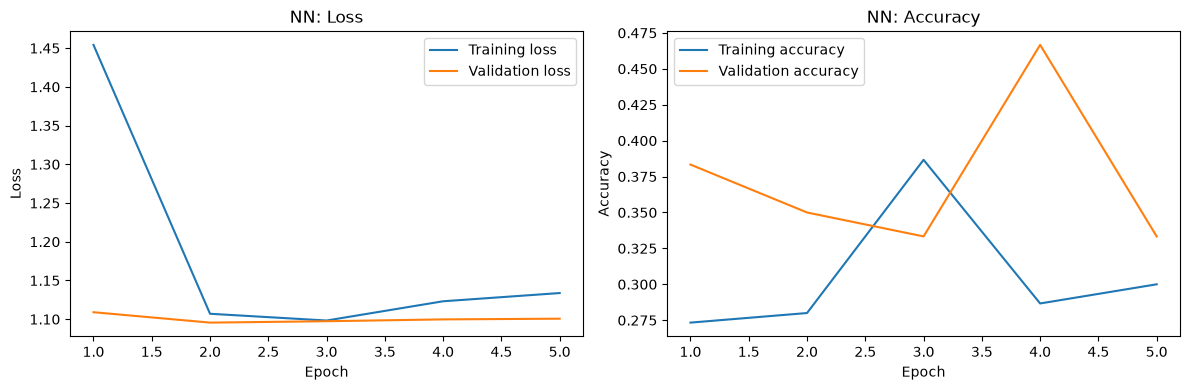

In [11]:
# plot learning curves from history
plot_learning_curves(history, config, file_name=f'{filename}_disease_recognition_learning_curve')

relevant directories created ... 
Test loss: 1.0918
Test accuracy: 0.3400
----------------------------------------
Classification Report
----------------------------------------


              precision    recall  f1-score   support

     Healthy       0.00      0.00      0.00        50
     Powdery       1.00      0.02      0.04        50
        Rust       0.34      1.00      0.50        50

    accuracy                           0.34       150
   macro avg       0.45      0.34      0.18       150
weighted avg       0.45      0.34      0.18       150



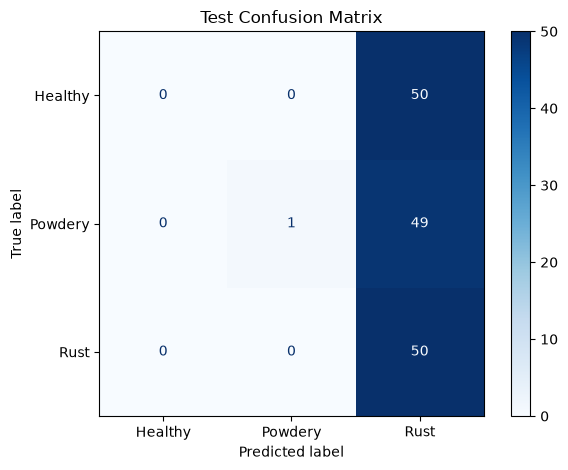

In [14]:
# check if we can load history and models from the saved files
history_pytorch_nn = torch.load(f"{config.model_dir}/{filename}_history.pt")
state_dict = torch.load(f"{config.model_dir}/{filename}_state_dict.pth")
loaded_model = NeuralNetwork()
loaded_model.load_state_dict(state_dict)

# get the metrics on test dataset
test_loss, test_accuracy, all_predictions, all_labels, cm, classification_report = test_model(loaded_model, test_dl, criterion, train_data.class_names, device, config, file_name='confusion_matrix', plot_confusion_matrix=True)